# Weather data — rough EDA (Somei-yoshino stations)
Working notebook behind the cleaning rules in `02_clean_weather_and_features.py`.
The polished version is `04_eda_weather_report.py` → `reference/weather-eda.html`.

1. Raw data: shape, missing values, JMA quality codes
2. Gaps: where and how long
3. Consistency checks and outliers
4. Station relocations (homogeneity numbers)
5. Cleaned data: what imputation changed, does it work
6. Distributions and seasonal cycle
7. Feature table: missing values, correlations, first look at bloom timing

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
PROJECT_DIR = Path("../..").resolve()          # run from src/02_preprocess
RAW_DIR = PROJECT_DIR / "data/raw/weather_by_station"
META_DIR = PROJECT_DIR / "data/processed/01_source_data/01_station_metadata"
CLEAN_DIR = PROJECT_DIR / "data/processed/02_cleaned_source_data/weather"

T, X, N, P, S = ("mean_temperature_c", "maximum_temperature_c", "minimum_temperature_c",
                 "precipitation_mm", "sunshine_duration_hours")
VARS = [T, X, N, P, S]

## 1. Raw data

In [2]:
names = pd.read_csv(META_DIR / "01_01_station_name.csv", dtype={"station_id": str})
elev = pd.read_csv(META_DIR / "01_02_station_elevations.csv", dtype={"station_id": str}, encoding="utf-8-sig")
species = pd.read_csv(META_DIR / "01_03_cherry_species.csv", dtype={"station_id": str})
meta = names.merge(elev).merge(species)
meta = meta[meta.cherry_species == "Somei-yoshino"]
print("Somei-yoshino stations:", len(meta))
meta.head()

Somei-yoshino stations: 82


,station_id,location,jma_station_id,prefecture,region,latitude,longitude,elevation_m,cherry_species
4,412,Sapporo,s47412,Hokkaido,Hokkaido,43.060000,141.328333,17.4,Somei-yoshino
9,423,Muroran,s47423,Hokkaido,Hokkaido,42.311667,140.975000,39.9,Somei-yoshino
11,428,Esashi,s47428,Hokkaido,Hokkaido,41.866667,140.123333,3.7,Somei-yoshino
12,430,Hakodate,s47430,Hokkaido,Hokkaido,41.816667,140.753333,35.0,Somei-yoshino
13,433,Kutchan,s47433,Hokkaido,Hokkaido,42.900000,140.756667,176.1,Somei-yoshino


In [3]:
files = sorted(RAW_DIR.glob("weather_*_daily_quality.csv"))
raw = pd.concat([pd.read_csv(f, dtype={"station_id": str}) for f in files], ignore_index=True)
raw = raw[raw.station_id.isin(meta.station_id)].reset_index(drop=True)
raw["date"] = pd.to_datetime(raw.date)
raw["year"] = raw.date.dt.year
print(raw.shape)
print("stations:", raw.station_id.nunique(), "| dates:", raw.date.min().date(), "to", raw.date.max().date())
raw[["station_id", "location", "date"] + VARS].head()

(2216378, 24)
stations: 82 | dates: 1952-01-01 to 2025-12-31


,station_id,location,date,mean_temperature_c,maximum_temperature_c,minimum_temperature_c,precipitation_mm,sunshine_duration_hours
0,602,Aikawa,1952-01-01,6.3,12.0,3.6,2.9,NaN
1,602,Aikawa,1952-01-02,3.6,4.3,2.4,0.0,NaN
2,602,Aikawa,1952-01-03,4.5,6.0,2.4,0.0,NaN
3,602,Aikawa,1952-01-04,6.5,9.4,3.8,12.9,NaN
4,602,Aikawa,1952-01-05,3.8,6.4,1.5,16.9,NaN


In [4]:
# every station should have every day 1952-2025
days_per_station = raw.groupby("station_id").size()
print(days_per_station.unique(), "expected:", len(pd.date_range("1952-01-01", "2025-12-31")))
print("duplicate station-dates:", raw.duplicated(["station_id", "date"]).sum())

[27029] expected: 27029
duplicate station-dates: 0


In [5]:
raw[VARS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,2199410.0,14.57,8.62,-20.6,7.5,15.1,21.6,34.2
maximum_temperature_c,2199339.0,18.98,8.85,-12.8,12.0,19.6,26.0,41.4
minimum_temperature_c,2199370.0,10.73,8.95,-32.5,3.2,10.8,18.4,30.8
precipitation_mm,2199866.0,4.99,14.18,0.0,0.0,0.0,3.2,806.0
sunshine_duration_hours,1965219.0,5.28,4.02,0.0,1.2,5.3,8.8,14.7


In [6]:
# missing values per variable
miss = raw[VARS].isna().sum().to_frame("missing")
miss["pct"] = (miss.missing / len(raw) * 100).round(2)
miss

,missing,pct
mean_temperature_c,16968,0.77
maximum_temperature_c,17039,0.77
minimum_temperature_c,17008,0.77
precipitation_mm,16512,0.74
sunshine_duration_hours,251159,11.33


JMA quality codes: 8 normal, 5 quasi-normal, 4 insufficient data, 1 missing, 0 not observed.

In [7]:
qc = pd.DataFrame({v: raw[f"{v}_quality_code"].value_counts() for v in VARS}).fillna(0).astype(int)
qc

,mean_temperature_c,maximum_temperature_c,minimum_temperature_c,precipitation_mm,sunshine_duration_hours
0,15747,15747,15747,15747,248831
1,1221,1292,1261,765,2328
4,307,298,235,714,1767
5,1158,1593,1048,973,1983
8,2197945,2197448,2198087,2198179,1961469


In [8]:
# are the missing values exactly the codes 0/1?
for v in VARS:
    print(v, raw.loc[raw[v].isna(), f"{v}_quality_code"].value_counts().to_dict())

mean_temperature_c {0: 15747, 1: 1221}
maximum_temperature_c {0: 15747, 1: 1292}
minimum_temperature_c {0: 15747, 1: 1261}
precipitation_mm {0: 15747, 1: 765}
sunshine_duration_hours {0: 248831, 1: 2328}


In [9]:
# code 4 values exist but are biased (too many hourly obs missing) -> treat as missing
raw[raw[f"{T}_quality_code"] == 4][["location", "date", T, X, N]].head(10)

,location,date,mean_temperature_c,maximum_temperature_c,minimum_temperature_c
20336,Aikawa,2007-09-05,25.5,30.0,22.1
21695,Aikawa,2011-05-26,14.3,17.7,10.0
25750,Aikawa,2022-07-02,25.6,30.6,22.8
48710,Akita,2011-05-12,13.6,25.6,9.4
48962,Akita,2012-01-19,0.2,3.6,-3.8
52320,Akita,2021-03-30,11.7,15.7,7.8
75809,Aomori,2011-07-21,17.6,20.9,16.3
102725,Choshi,2011-03-30,10.5,14.6,7.0
124427,Esashi,1996-08-28,21.0,24.0,NaN
124930,Esashi,1998-01-13,0.2,NaN,-3.4


## 2. Gaps

In [10]:
def missing_runs(s):
    """lengths and start dates of consecutive NaN runs in a date-sorted series"""
    isna = s.isna().to_numpy()
    runs, i = [], 0
    while i < len(isna):
        if isna[i]:
            j = i
            while j + 1 < len(isna) and isna[j + 1]:
                j += 1
            runs.append((i, j - i + 1))
            i = j + 1
        else:
            i += 1
    return runs

rows = []
for sid, g in raw.sort_values(["station_id", "date"]).groupby("station_id"):
    g = g.reset_index(drop=True)
    for start, length in missing_runs(g[T]):
        rows.append({"station_id": sid, "location": g.location[0], "start": g.date[start].date(),
                     "length": length, "leading": start == 0})
runs = pd.DataFrame(rows)
print("temperature gap runs:", len(runs))
pd.cut(runs.length, [0, 1, 3, 7, 30, 60, 365, 1e5]).value_counts().sort_index()

temperature gap runs: 50


length
(0.0, 1.0]           23
(1.0, 3.0]           10
(3.0, 7.0]            5
(7.0, 30.0]           2
(30.0, 60.0]          1
(60.0, 365.0]         3
(365.0, 100000.0]     6
Name: count, dtype: int64

In [11]:
# long gaps: mostly 'leading' = station had not started observing yet
runs[runs.length > 30].sort_values("length", ascending=False)

,station_id,location,start,length,leading
19,672,Tateyama,1952-01-01,5975,True
48,843,Fukue,1952-01-01,3773,True
41,822,Nobeoka,1952-01-01,3439,True
5,520,Shinjo,1952-01-01,2070,True
39,780,Nara,1952-01-01,486,True
24,677,Miyakejima,2000-09-18,409,False
9,598,Onahama,1977-05-27,330,False
12,598,Onahama,1978-06-16,181,False
13,598,Onahama,1978-12-15,146,False
11,598,Onahama,1978-04-27,49,False


In [12]:
# first year with temperature data, per station
first_temp = raw[raw[T].notna()].groupby("location").year.min()
first_temp[first_temp > 1952].sort_values()

location
Nara        1953
Shinjo      1957
Nobeoka     1961
Fukue       1962
Tateyama    1968
Name: year, dtype: int32

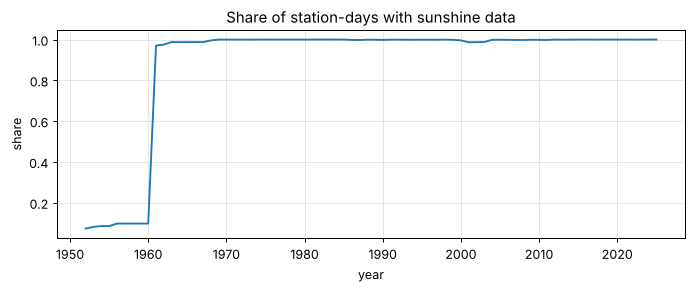

In [13]:
# sunshine: share of stations with data, per year
sun_share = raw.groupby("year")[S].apply(lambda s: s.notna().mean())
sun_share.plot(figsize=(9, 3), title="Share of station-days with sunshine data")
plt.ylabel("share"); plt.grid(alpha=.3)

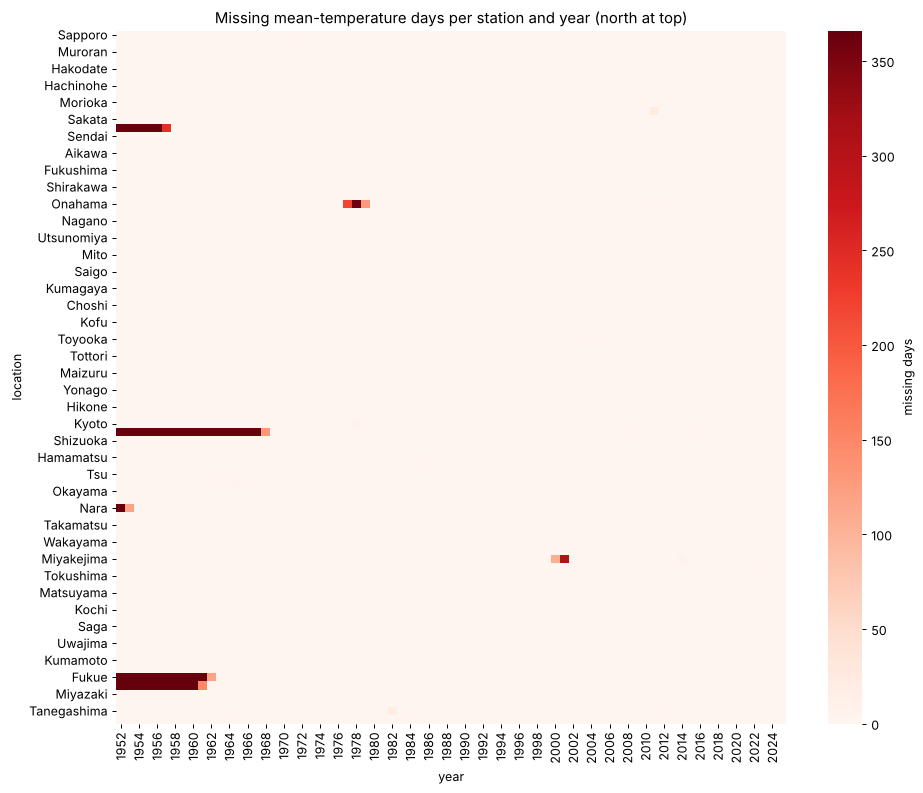

In [14]:
# missing days by station x year (temperature), quick heatmap
pivot = raw.assign(m=raw[T].isna()).groupby(["location", "year"]).m.sum().unstack()
order = meta.sort_values("latitude", ascending=False).location
plt.figure(figsize=(12, 10))
sns.heatmap(pivot.reindex(order), cmap="Reds", cbar_kws={"label": "missing days"})
plt.title("Missing mean-temperature days per station and year (north at top)")

## 3. Consistency checks and outliers

In [15]:
print("min > max:", (raw[N] > raw[X]).sum())
print("mean > max:", (raw[T] > raw[X] + 0.05).sum())
print("mean < min:", (raw[T] < raw[N] - 0.05).sum())

min > max: 0
mean > max: 0
mean < min: 7662


In [16]:
# mean < min only happens 1953-1963 -> JMA used a different day boundary for max/min then
bad = raw[T] < raw[N] - 0.05
bad.groupby(raw.year).sum().loc[lambda s: s > 0]

year
1953    572
1954    739
1955    739
1956    743
1957    653
1958    662
1959    667
1960    785
1961    835
1962    668
1963    599
dtype: int64

In [17]:
(raw.loc[bad, N] - raw.loc[bad, T]).describe()

count    7662.000000
mean        0.702819
std         0.655159
min         0.100000
25%         0.200000
50%         0.500000
75%         1.000000
max         7.000000
dtype: float64

In [18]:
# range checks
print("precip < 0:", (raw[P] < 0).sum(), "| sunshine < 0:", (raw[S] < 0).sum(), "| sunshine > 15h:", (raw[S] > 15).sum())
print("max temp range:", raw[X].min(), raw[X].max(), "| min temp range:", raw[N].min(), raw[N].max())

precip < 0: 0 | sunshine < 0: 0 | sunshine > 15h: 0
max temp range: -12.8 41.4 | min temp range: -32.5 30.8


In [19]:
# outliers vs each station's normal for that day of year
raw["doy"] = raw.date.dt.dayofyear
for v in [T, X, N]:
    anom = raw[v] - raw.groupby(["station_id", "doy"])[v].transform("mean")
    raw[f"z_{v}"] = anom / anom.groupby(raw.station_id).transform("std")
z = raw[[f"z_{v}" for v in [T, X, N]]].abs().max(axis=1)
print("days with |z| > 5:", (z > 5).sum())
raw.loc[z.nlargest(10).index, ["location", "date", T, X, N]]

days with |z| > 5: 65


,location,date,mean_temperature_c,maximum_temperature_c,minimum_temperature_c
1355144,Owase,1962-02-11,20.8,27.1,8.8
1918377,Toyama,2024-02-19,17.5,20.9,15.1
1274057,Onahama,1962-02-11,11.4,24.8,3.2
1692702,Takada,1998-04-13,25.4,31.3,21.0
784629,Maizuru,1954-02-27,19.5,22.9,16.4
107369,Choshi,2023-12-16,20.0,22.3,18.7
1908934,Toyama,1998-04-13,25.0,30.6,21.9
465729,Iida,1969-01-27,14.9,19.4,9.3
703460,Kutchan,1953-12-07,-16.0,-7.6,-27.0
1919847,Toyooka,1954-02-27,18.6,20.8,12.7


Checked a few against neighbouring stations on the same day (e.g. Toyama & Takada 1998-04-13 both ~31 °C,
Toyama 2024-02-19 foehn). They look like real weather, so nothing is removed as an outlier.

In [20]:
# cross-check: Toyama vs Takada (neighbours) around 1998-04-13
chk = raw[raw.location.isin(["Toyama", "Takada"]) & raw.date.between("1998-04-10", "1998-04-16")]
chk.pivot(index="date", columns="location", values=X)

location,Takada,Toyama
date,,
1998-04-10,17.2,20.0
1998-04-11,20.8,19.2
1998-04-12,29.2,25.9
1998-04-13,31.3,30.6
1998-04-14,21.6,23.3
1998-04-15,15.6,17.2
1998-04-16,16.1,17.3


## 4. Station relocations

In [21]:
# homogeneity number changes = station move / instrument change
h = f"{T}_homogeneity_number"
chg = raw.sort_values(["station_id", "date"])
chg = chg[chg.groupby("station_id")[h].diff().fillna(0).ne(0)]
print("changes:", len(chg))
chg[["location", "date", h]].head(12)

changes: 54


,location,date,mean_temperature_c_homogeneity_number
1553011,Shinjo,1985-11-01,2
1553072,Shinjo,1986-01-01,1
1439176,Sakata,1970-03-06,2
1439477,Sakata,1971-01-01,1
15893,Aikawa,1995-07-07,2
16071,Aikawa,1996-01-01,1
1184341,Niigata,2012-06-28,2
1184528,Niigata,2013-01-01,1
555120,Kanazawa,1991-10-23,2
555190,Kanazawa,1992-01-01,1


In [22]:
# half of the changes fall on 1 Jan -> artefact: the number restarts in every 1-year download
print("on 1 Jan:", (chg.date.dt.strftime("%m-%d") == "01-01").sum(), "of", len(chg))
real = chg[chg.date.dt.strftime("%m-%d") != "01-01"]
print("real breaks:", len(real), "at", real.station_id.nunique(), "stations")

on 1 Jan: 27 of 54
real breaks: 27 at 26 stations


## 5. Cleaned data — what changed

In [23]:
daily = pd.read_csv(CLEAN_DIR / "02_cleaned_weather_daily_somei_1952_2025.csv.gz", dtype={"station_id": str})
daily["date"] = pd.to_datetime(daily.date)
print(daily.shape)
daily.head()

(2216378, 12)


,date,station_id,mean_temperature_c,mean_temperature_flag,maximum_temperature_c,maximum_temperature_flag,minimum_temperature_c,minimum_temperature_flag,precipitation_mm,sunshine_duration_hours,temp_imputed,pre_1964_mean_below_min
0,1952-01-01,412,-1.2,observed,4.4,observed,-2.9,observed,1.5,NaN,0,0
1,1952-01-02,412,-1.7,observed,1.4,observed,-5.3,observed,0.0,NaN,0,0
2,1952-01-03,412,-4.6,observed,-0.3,observed,-10.2,observed,6.1,NaN,0,0
3,1952-01-04,412,-1.3,observed,2.8,observed,-5.1,observed,1.5,NaN,0,0
4,1952-01-05,412,-3.4,observed,-0.8,observed,-8.0,observed,5.3,NaN,0,0


In [24]:
pd.DataFrame({v: daily[v.replace("_c", "_flag")].value_counts() for v in [T, X, N]}).fillna(0).astype(int)

,mean_temperature_c,maximum_temperature_c,minimum_temperature_c
imputed_linear,3,0,0
imputed_neighbour,413,471,377
missing_long_gap,1067,1123,1123
missing_no_donor,49,0,0
not_yet_observed,15743,15743,15743
observed,2199103,2199041,2199135


In [25]:
# missing before vs after cleaning
pd.DataFrame({"raw": raw[VARS].isna().sum() + pd.Series({v: (raw[f"{v}_quality_code"] == 4).sum() for v in VARS}),
              "cleaned": daily[VARS].isna().sum()})

,raw,cleaned
mean_temperature_c,17275,16859
maximum_temperature_c,17337,16863
minimum_temperature_c,17243,16863
precipitation_mm,17226,17226
sunshine_duration_hours,252926,252926


In [26]:
# what is still missing after 1964 (temperature)
left = daily[(daily.date.dt.year >= 1964) & daily[T].isna()]
left.merge(meta[["station_id", "location"]]).groupby("location").date.agg(["min", "max", "count"])

,min,max,count
location,,,
Miyakejima,2000-09-17,2001-10-31,410
Onahama,1977-05-27,1979-05-09,706
Tateyama,1964-01-01,1968-05-10,1592


In [27]:
# imputation test: hide real data, refill, compare (from 06_weather_imputation_validation_somei.csv)
val = pd.read_csv(CLEAN_DIR / "06_weather_imputation_validation_somei.csv")
val.groupby("gap_length")[["mae_neighbour", "mae_linear"]].mean().round(2)

,mae_neighbour,mae_linear
gap_length,,
1,0.78,1.31
2,0.80,1.84
3,0.78,1.79
5,0.80,2.36
7,0.80,2.11
10,0.80,2.15
15,0.79,2.26
30,0.82,2.53
60,0.83,2.70


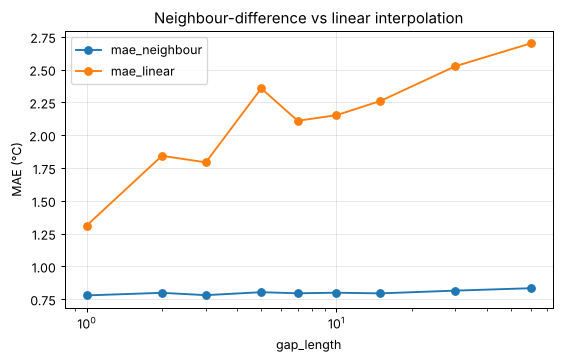

In [28]:
val.groupby("gap_length")[["mae_neighbour", "mae_linear"]].mean().plot(marker="o", logx=True, figsize=(7, 4))
plt.ylabel("MAE (°C)"); plt.title("Neighbour-difference vs linear interpolation"); plt.grid(alpha=.3)

In [29]:
val.groupby("variable")[["mae_neighbour", "mae_linear"]].mean().round(2)

,mae_neighbour,mae_linear
variable,,
maximum_temperature_c,0.98,2.52
mean_temperature_c,0.60,1.79
minimum_temperature_c,0.82,2.05


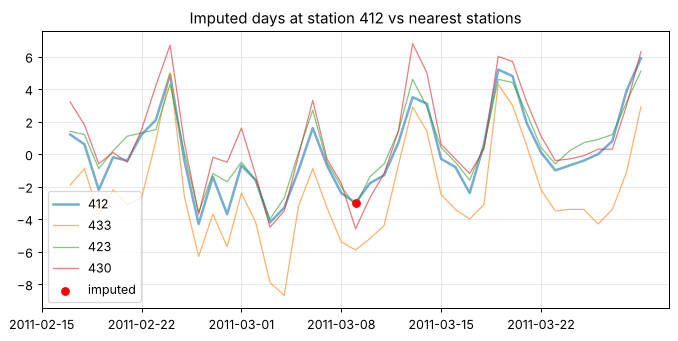

In [30]:
# example: an imputed stretch next to its neighbours
gap = daily[daily[T.replace("_c", "_flag")] == "imputed_neighbour"].iloc[0]
win = daily[(daily.date - gap.date).abs() <= pd.Timedelta(days=20)]
sid = gap.station_id
others = meta.assign(d=np.hypot(meta.latitude - meta.set_index("station_id").latitude[sid],
                                meta.longitude - meta.set_index("station_id").longitude[sid])
                     ).nsmallest(4, "d").station_id
fig, ax = plt.subplots(figsize=(9, 4))
for o in others:
    w = win[win.station_id == o]
    ax.plot(w.date, w[T], alpha=.6, label=o, lw=2 if o == sid else 1)
imp = win[(win.station_id == sid) & (win[T.replace("_c", "_flag")] == "imputed_neighbour")]
ax.scatter(imp.date, imp[T], color="red", zorder=5, label="imputed")
ax.legend(); ax.set_title(f"Imputed days at station {sid} vs nearest stations"); ax.grid(alpha=.3)

## 6. Distributions and seasonal cycle

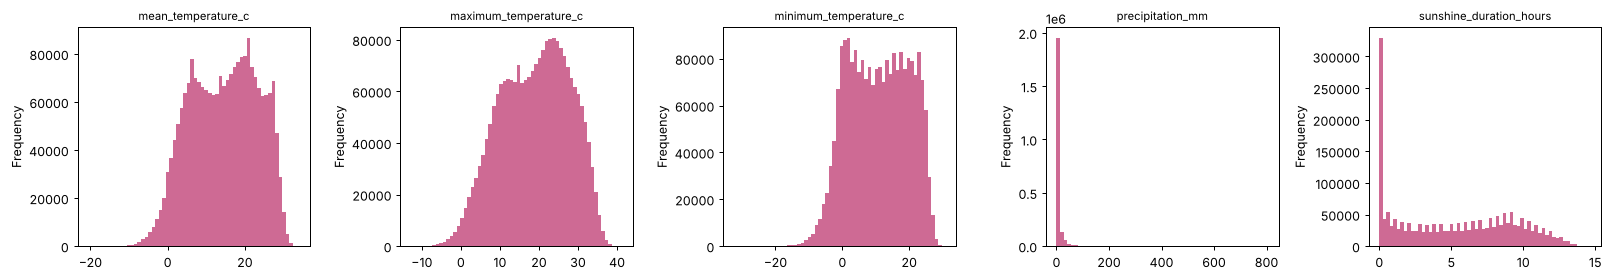

In [31]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, v in zip(axes, VARS):
    daily[v].dropna().plot.hist(bins=60, ax=ax, color="#c2457a", alpha=.8)
    ax.set_title(v, fontsize=9)
plt.tight_layout()

In [32]:
# precipitation is very skewed: most days are dry
print("dry days (0 mm):", (daily[P] == 0).mean().round(3))
daily[P].quantile([.5, .75, .9, .99, .999])

dry days (0 mm): 0.586


0.500      0.0
0.750      3.2
0.900     15.0
0.990     65.0
0.999    155.5
Name: precipitation_mm, dtype: float64

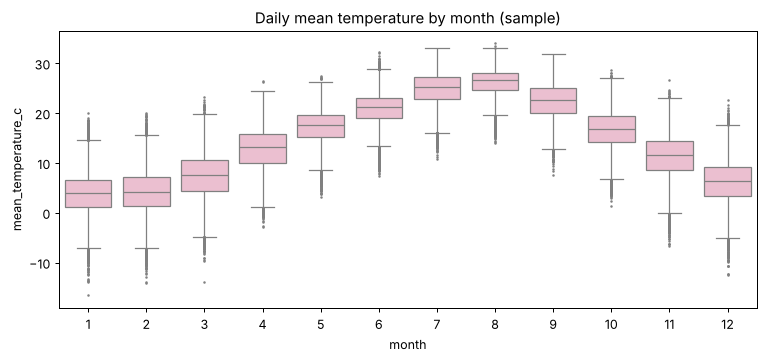

In [33]:
daily["month"] = daily.date.dt.month
plt.figure(figsize=(10, 4))
sns.boxplot(data=daily.sample(200_000, random_state=1), x="month", y=T, color="#f2b8cf", fliersize=1)
plt.title("Daily mean temperature by month (sample)")

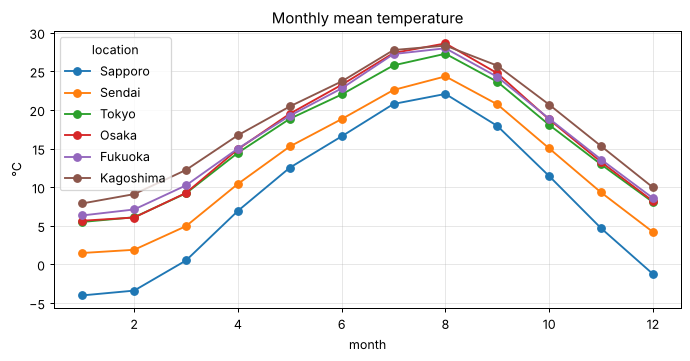

In [34]:
# north vs south: monthly mean climatology for a few stations
pick = ["Sapporo", "Sendai", "Tokyo", "Osaka", "Fukuoka", "Kagoshima"]
clim = (daily.merge(meta[["station_id", "location"]]).query("location in @pick")
        .groupby(["location", "month"])[T].mean().unstack(0))
clim[[p for p in pick if p in clim]].plot(figsize=(9, 4), marker="o")
plt.ylabel("°C"); plt.title("Monthly mean temperature"); plt.grid(alpha=.3)

## 7. Feature table

In [35]:
feat = pd.read_csv(CLEAN_DIR / "03_weather_features_somei_station_year.csv", dtype={"station_id": str})
print(feat.shape)
feat.head()

(5986, 47)


,station_id,location,prefecture,region,cherry_species,latitude,longitude,elevation_m,year,flowering_date,flowering_doy,full_bloom_date,full_bloom_doy,bloom_interval_days,tmean_oct,tmean_nov,tmean_dec,tmean_jan,tmax_jan,tmin_jan,tmean_feb,tmax_feb,tmin_feb,tmean_mar,tmax_mar,tmin_mar,tmean_apr,chill_days_0_7c_nov_feb,tmin_lowest_nov_feb,frost_days_jan_mar,gdd5_feb1_to_feb_end,cum_tmax_feb1_to_feb_end,cum_tmean_feb1_to_feb_end,gdd5_feb1_to_mar_end,cum_tmax_feb1_to_mar_end,cum_tmean_feb1_to_mar_end,precip_feb_mar_mm,precip_feb_mar_missing_days,sunshine_feb_mar_h,sunshine_feb_mar_missing_days,rule600_tmax_pred_doy,rule400_tmean_pred_doy,temp_missing_days_oct_may,temp_imputed_days_oct_may,season_temp_complete,relocations_before_season,pre_1964_definition
0,412,Sapporo,Hokkaido,Hokkaido,Somei-yoshino,43.06,141.33,17.4,1953,1953-05-07,127.0,1953-05-14,134.0,7.0,10.53,1.53,-6.02,-6.57,-3.15,-10.62,-6.07,-1.51,-11.50,0.05,3.91,-3.92,5.50,23.0,-20.0,82.0,0.2,-42.2,-170.0,1.0,79.0,-168.3,143.4,0,NaN,59,132.0,155.0,0,0,1,0,1
1,412,Sapporo,Hokkaido,Hokkaido,Somei-yoshino,43.06,141.33,17.4,1954,1954-05-04,124.0,1954-05-08,128.0,4.0,10.30,0.26,-1.82,-5.44,-1.71,-10.05,-3.06,1.03,-7.39,-1.26,3.11,-5.73,6.77,30.0,-20.9,84.0,0.0,28.9,-85.6,0.0,125.2,-124.8,108.9,0,NaN,59,127.0,151.0,0,0,1,0,1
2,412,Sapporo,Hokkaido,Hokkaido,Somei-yoshino,43.06,141.33,17.4,1955,1955-05-11,131.0,1955-05-16,136.0,5.0,9.40,3.65,-0.74,-5.79,-1.96,-10.84,-3.71,0.17,-8.34,-0.80,3.28,-4.73,5.99,33.0,-17.6,86.0,0.0,4.7,-103.9,0.0,106.4,-128.8,225.6,0,NaN,59,132.0,154.0,0,0,1,0,1
3,412,Sapporo,Hokkaido,Hokkaido,Somei-yoshino,43.06,141.33,17.4,1956,1956-05-04,125.0,1956-05-09,130.0,5.0,10.77,3.77,-0.09,-5.20,-1.50,-8.99,-4.55,0.30,-9.01,-0.04,3.80,-3.60,6.31,38.0,-15.3,84.0,0.0,8.6,-132.0,0.6,126.4,-133.3,141.0,0,NaN,60,128.0,147.0,0,0,1,0,1
4,412,Sapporo,Hokkaido,Hokkaido,Somei-yoshino,43.06,141.33,17.4,1957,1957-05-09,129.0,1957-05-13,133.0,4.0,11.85,3.48,-3.80,-4.22,-0.13,-8.72,-5.14,-0.66,-9.53,-1.87,2.27,-5.64,6.49,15.0,-18.4,88.0,0.0,-18.5,-144.0,0.0,51.8,-201.9,143.6,0,NaN,59,132.0,154.0,0,0,1,0,1


In [36]:
feat.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
latitude,5986.0,35.84,2.65,30.38,34.20,35.44,36.95,43.06
longitude,5986.0,136.49,3.61,128.83,133.55,136.83,139.84,141.96
elevation_m,5986.0,63.38,121.18,0.50,5.30,19.65,45.90,610.00
year,5986.0,1989.00,21.07,1953.00,1971.00,1989.00,2007.00,2025.00
flowering_doy,5192.0,94.38,12.32,69.00,86.00,92.00,100.00,146.00
full_bloom_doy,5161.0,101.01,11.02,78.00,94.00,98.00,105.00,151.00
bloom_interval_days,5142.0,6.61,2.75,1.00,5.00,6.00,8.00,26.00
tmean_oct,5941.0,16.75,2.77,6.71,15.07,17.07,18.65,24.64
tmean_nov,5942.0,11.34,3.25,-1.24,9.35,11.75,13.47,20.59
tmean_dec,5943.0,6.25,3.45,-7.51,4.17,6.75,8.47,15.56


In [37]:
# missing values in the feature table
fm = feat.isna().sum()
fm[fm > 0].to_frame("missing")

,missing
flowering_date,794
flowering_doy,794
full_bloom_date,825
full_bloom_doy,825
bloom_interval_days,844
tmean_oct,45
tmean_nov,44
tmean_dec,43
tmean_jan,44
tmax_jan,44


In [38]:
# after the suggested modelling filter
model = feat[(feat.year >= 1964) & (feat.season_temp_complete == 1) & feat.flowering_doy.notna()]
print(model.shape)
fm = model.isna().sum()
fm[fm > 0]

(4376, 47)


full_bloom_date        19
full_bloom_doy         19
bloom_interval_days    19
dtype: int64

In [39]:
# missing flowering dates by decade (station observations stopping after JMA automation)
feat.assign(decade=feat.year // 10 * 10).groupby("decade").flowering_doy.apply(lambda s: s.isna().sum())

decade
1950     62
1960     50
1970     14
1980     10
1990     15
2000    104
2010    335
2020    204
Name: flowering_doy, dtype: int64

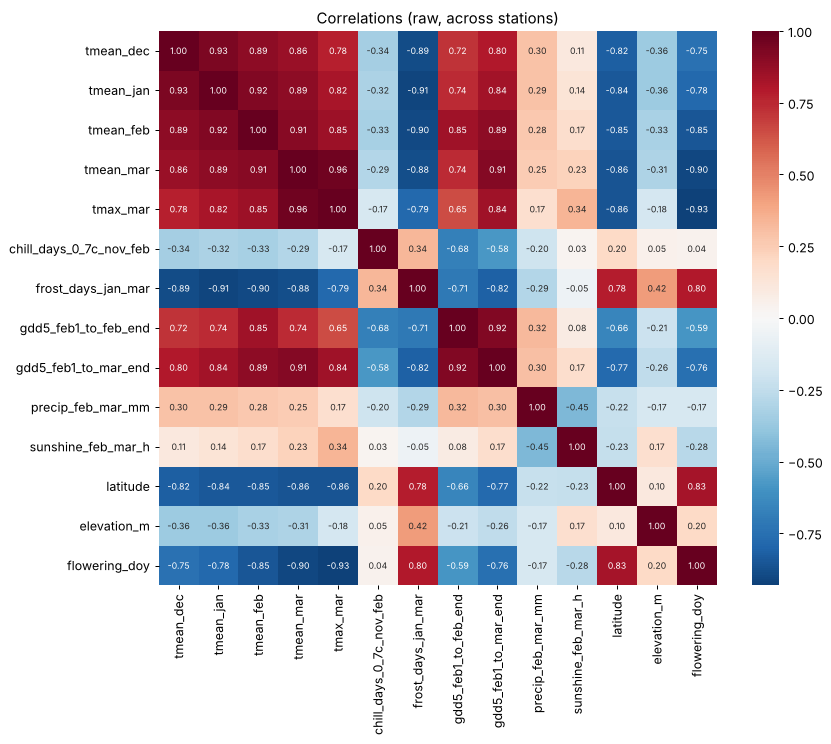

In [40]:
wx_cols = ["tmean_dec", "tmean_jan", "tmean_feb", "tmean_mar", "tmax_mar", "chill_days_0_7c_nov_feb",
           "frost_days_jan_mar", "gdd5_feb1_to_feb_end", "gdd5_feb1_to_mar_end", "precip_feb_mar_mm",
           "sunshine_feb_mar_h", "latitude", "elevation_m"]
plt.figure(figsize=(10, 8))
sns.heatmap(model[wx_cols + ["flowering_doy"]].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Correlations (raw, across stations)")

In [41]:
# latitude dominates. Remove each station's mean to see the year-to-year effect
anom = model[wx_cols[:-2] + ["flowering_doy"]] - model.groupby("station_id")[wx_cols[:-2] + ["flowering_doy"]].transform("mean")
pd.DataFrame({"raw": model[wx_cols[:-2]].corrwith(model.flowering_doy),
              "within_station": anom[wx_cols[:-2]].corrwith(anom.flowering_doy)}).round(2).sort_values("within_station")

,raw,within_station
tmean_mar,-0.90,-0.78
tmax_mar,-0.93,-0.78
gdd5_feb1_to_mar_end,-0.76,-0.70
tmean_feb,-0.85,-0.57
gdd5_feb1_to_feb_end,-0.59,-0.41
tmean_jan,-0.78,-0.25
tmean_dec,-0.75,-0.10
precip_feb_mar_mm,-0.17,-0.06
sunshine_feb_mar_h,-0.28,0.02
chill_days_0_7c_nov_feb,0.04,0.07


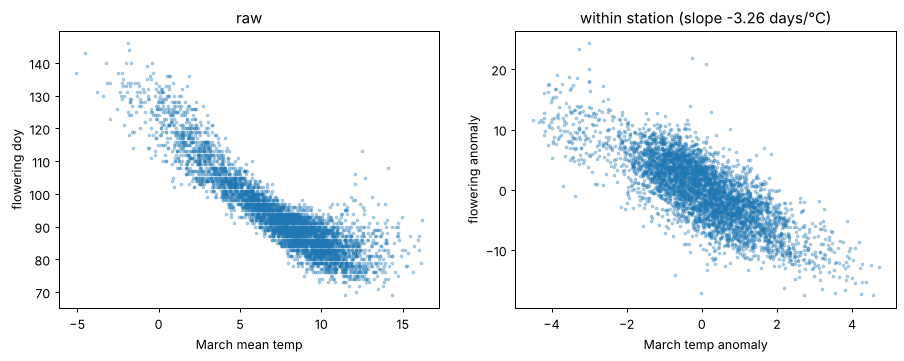

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(model.tmean_mar, model.flowering_doy, s=4, alpha=.3)
axes[0].set_xlabel("March mean temp"); axes[0].set_ylabel("flowering doy"); axes[0].set_title("raw")
axes[1].scatter(anom.tmean_mar, anom.flowering_doy, s=4, alpha=.3)
slope = np.polyfit(anom.tmean_mar, anom.flowering_doy, 1)[0]
axes[1].set_title(f"within station (slope {slope:.2f} days/°C)")
axes[1].set_xlabel("March temp anomaly"); axes[1].set_ylabel("flowering anomaly")

trend °C/decade: 0.42


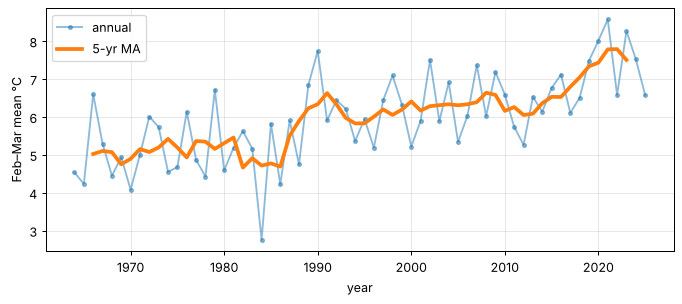

In [43]:
# late-winter warming trend
fm_temp = feat[feat.year >= 1964].assign(fm=lambda d: (d.tmean_feb + d.tmean_mar) / 2).groupby("year").fm.mean()
ax = fm_temp.plot(figsize=(9, 3.5), marker="o", ms=3, alpha=.5, label="annual")
fm_temp.rolling(5, center=True).mean().plot(ax=ax, lw=3, label="5-yr MA")
print("trend °C/decade:", round(np.polyfit(fm_temp.index, fm_temp.values, 1)[0] * 10, 2))
ax.legend(); ax.set_ylabel("Feb–Mar mean °C"); ax.grid(alpha=.3)

## Notes / to discuss
- Start modelling in 1964 (pre-1964 mean/min definition issue); 1961+ only if sunshine is used.
- Temperature gaps ≤ 60 days filled from neighbours (~0.8 °C MAE); longer gaps (Onahama 1977–79,
  Miyakejima 2000–01) and pre-observation periods (Tateyama to 1968) left missing.
- Precipitation and sunshine not imputed; both carry weak within-station signal.
- Use station effects or anomalies — raw correlations mostly reflect latitude.
- If forecasting on 1 March, use only features up to end of February.